# Notebook dedicated to study the time residual and the correlated integrated directionality (CID) distribution and define optimized cuts for directionality

In [2]:
import numpy as np
import glob 
import matplotlib.pyplot as plt
import seaborn as sn

# Load the Data

In [10]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/resume_npz/'
flist = sorted(glob.glob(fdir + 'e_*MeV_resumed.npz'))

observable_list = ['energy_mc', 'energy_recon', 'pos_recon', 'time_residual_recons', 'hit_type', 'dir_angle_true_recons', 'dir_angle_true_mc', 'dir_angle_sun']

data_dict = {obs_i: [] for obs_i in observable_list}

for file_i in flist:
    np_data = np.load(file_i)

    for obs_i in observable_list:
        data_dict[obs_i].append(np_data[obs_i])

for obs_i in observable_list:
    data_dict[obs_i] = np.concatenate(data_dict[obs_i], axis = 0)

In [11]:
data_dict

{'energy_mc': array([2.5, 2.5, 2.5, ..., 5. , 5. , 5. ], shape=(14809556,)),
 'energy_recon': array([2.57386756, 2.57386756, 2.57386756, ..., 4.3637085 , 4.3637085 ,
        4.3637085 ], shape=(14809556,)),
 'pos_recon': array([[ 1853.82922363,   380.1111145 ,  1701.76391602],
        [ 1853.82922363,   380.1111145 ,  1701.76391602],
        [ 1853.82922363,   380.1111145 ,  1701.76391602],
        ...,
        [-4693.97753906, -2965.95507812,  2232.78857422],
        [-4693.97753906, -2965.95507812,  2232.78857422],
        [-4693.97753906, -2965.95507812,  2232.78857422]],
       shape=(14809556, 3)),
 'time_residual_recons': array([ -63.67925924,    0.72685176,   -1.6912813 , ...,  167.27253908,
         168.97610467, -612.40018576], shape=(14809556,)),
 'hit_type': array([2, 1, 2, ..., 2, 2, 0], shape=(14809556,)),
 'dir_angle_true_recons': array([ 0.51582851,  0.3326377 ,  0.43325446, ..., -0.45539179,
        -0.65983186,  0.35418435], shape=(14809556,)),
 'dir_angle_true_mc': ar

# Data Analysis & Plots

In [65]:
# ----- Extract Observables -----

energy_mc = data_dict['energy_mc']
time_residual_recons = data_dict['time_residual_recons']
hit_type = data_dict['hit_type']
dir_angle_true_recons = data_dict['dir_angle_true_recons']
dir_angle_true_mc = data_dict['dir_angle_true_mc']
dir_angle_sun = data_dict['dir_angle_sun']

# ----- Cuts on Data -----
tres_inf_cut = -4
tres_sup_cut = 1

tres_condition = (time_residual_recons >= tres_inf_cut) & (time_residual_recons <= tres_sup_cut)

energy_mc_cut = energy_mc[tres_condition]
time_residual_recons_cut = time_residual_recons[tres_condition]
hit_type_cut = hit_type[tres_condition]
dir_angle_true_recons_cut = dir_angle_true_recons[tres_condition]
dir_angle_sun_cut = dir_angle_sun[tres_condition]

# ----- Separate the PMT hit types -----
cher_hits_condition = (hit_type_cut == 1)
scint_hits_condition = (hit_type_cut == 2)
cher_scint_hits_condition = (hit_type_cut == 3)

energy_mc_cher = energy_mc_cut[cher_hits_condition]
energy_mc_scint = energy_mc_cut[scint_hits_condition]
energy_mc_cher_scint = energy_mc_cut[cher_scint_hits_condition]

tres_recons_cher = time_residual_recons_cut[cher_hits_condition]
tres_recons_scint = time_residual_recons_cut[scint_hits_condition]
tres_recons_cher_scint = time_residual_recons_cut[cher_scint_hits_condition]

dir_angle_true_recons_cher = dir_angle_true_recons_cut[cher_hits_condition]
dir_angle_true_recons_scint = dir_angle_true_recons_cut[scint_hits_condition]
dir_angle_true_recons_cher_scint = dir_angle_true_recons_cut[cher_scint_hits_condition]

## Time Residual

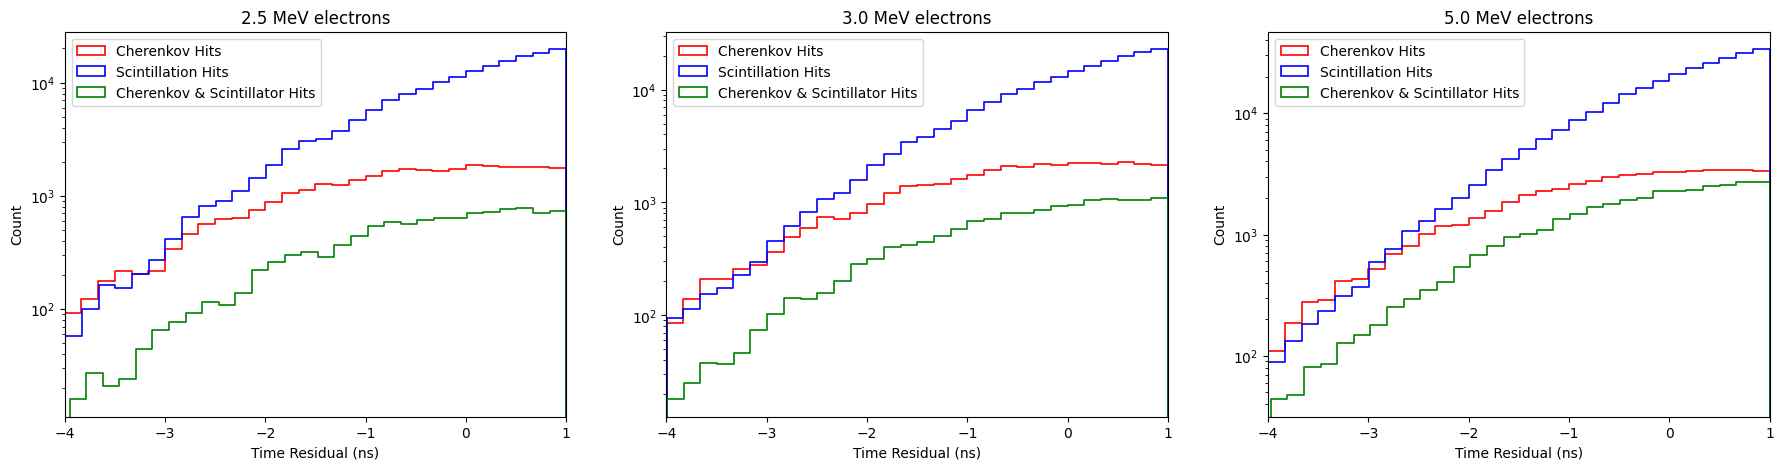

In [66]:
bins = 30

unique_energies = np.unique(energy_mc_cut)

fig, axes = plt.subplots(1, len(unique_energies), figsize = (22, 5))

for i_dx, energy_i in enumerate(unique_energies):

    axis = axes[i_dx]

    energy_mask_cher = (energy_mc_cher == energy_i)
    energy_mask_scint = (energy_mc_scint == energy_i)
    energy_mask_cher_scint = (energy_mc_cher_scint == energy_i)

    sn.histplot(tres_recons_cher[energy_mask_cher], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red', ax = axes[i_dx])
    sn.histplot(tres_recons_scint[energy_mask_scint], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', color = 'blue', ax = axes[i_dx])
    sn.histplot(tres_recons_cher_scint[energy_mask_cher_scint], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov & Scintillator Hits', color = 'green', ax = axes[i_dx])

    axis.set_xlabel('Time Residual (ns)')
    axis.legend(loc='best')
    axis.set_yscale('log')
    axis.set_xlim(tres_inf_cut, tres_sup_cut)
    axis.set_title(f'{energy_i} MeV electrons')

plt.show()

## CID 

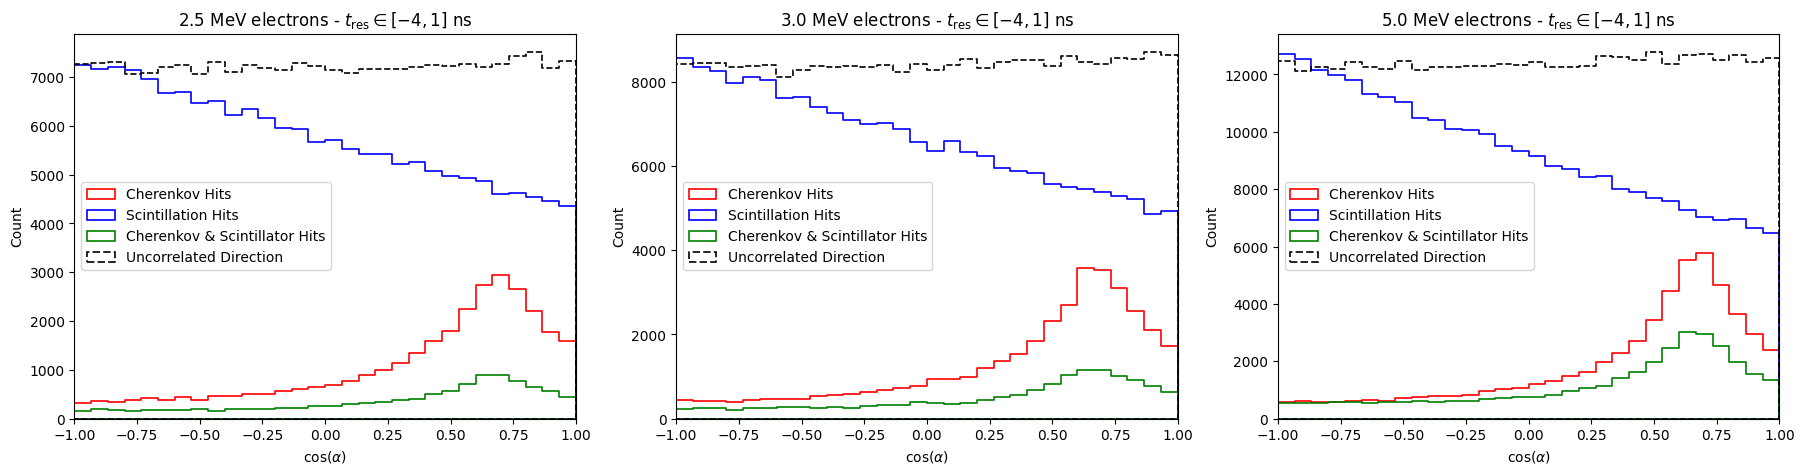

In [67]:
bins = 30

unique_energies = np.unique(energy_mc_cut)

fig, axes = plt.subplots(1, len(unique_energies), figsize = (22, 5))

for i_dx, energy_i in enumerate(unique_energies):

    axis = axes[i_dx]
    
    energy_mask = (energy_mc_cut == energy_i)
    energy_mask_cher = (energy_mc_cher == energy_i)
    energy_mask_scint = (energy_mc_scint == energy_i)
    energy_mask_cher_scint = (energy_mc_cher_scint == energy_i)

    sn.histplot(dir_angle_true_recons_cher[energy_mask_cher], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov Hits', color = 'red', ax = axes[i_dx])
    sn.histplot(dir_angle_true_recons_scint[energy_mask_scint], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scintillation Hits', color = 'blue', ax = axes[i_dx])
    sn.histplot(dir_angle_true_recons_cher_scint[energy_mask_cher_scint], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Cherenkov & Scintillator Hits', color = 'green', ax = axes[i_dx])
    sn.histplot(dir_angle_sun_cut[energy_mask], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Uncorrelated Direction', color = 'black', linestyle = '--',ax = axes[i_dx])

    axis.set_xlabel(r'$\cos(\alpha)$')
    axis.legend(loc='best')
    #axis.set_yscale('log')
    axis.set_xlim(-1, 1)
    axis.set_title(fr'{energy_i} MeV electrons - $t_\text{{res}} \in [{tres_inf_cut}, {tres_sup_cut}]$ ns')

plt.show()